<a href="https://colab.research.google.com/github/snigdhareddy-20/-DEEP_LEARNING/blob/main/DL_S6.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q numpy pandas matplotlib opencv-python pillow

In [2]:
import os
import json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

print("All libraries imported successfully!")


All libraries imported successfully!


In [4]:
from google.colab import files

uploaded = files.upload()


Saving indian_traffic_demo_dataset.zip to indian_traffic_demo_dataset.zip


In [5]:
import zipfile

zip_file = list(uploaded.keys())[0]

with zipfile.ZipFile(zip_file, 'r') as zip_ref:
    zip_ref.extractall('/content/traffic_dataset')

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [6]:
dataset_path = "/content/traffic_dataset"

for root, dirs, files_list in os.walk(dataset_path):
    print("Folder:", root)
    print("Number of files:", len(files_list))


Folder: /content/traffic_dataset
Number of files: 0
Folder: /content/traffic_dataset/indian_traffic_demo_dataset
Number of files: 2
Folder: /content/traffic_dataset/indian_traffic_demo_dataset/images
Number of files: 12


In [7]:
dataset_path = "/content/traffic_dataset/indian_traffic_demo_dataset"

images_path = os.path.join(dataset_path, "images")
annotation_path = os.path.join(dataset_path, "instances.json")

print("Dataset path:", dataset_path)
print("Images folder exists:", os.path.exists(images_path))
print("Annotation file exists:", os.path.exists(annotation_path))
print("Number of images:", len(os.listdir(images_path)))

Dataset path: /content/traffic_dataset/indian_traffic_demo_dataset
Images folder exists: True
Annotation file exists: True
Number of images: 12


In [8]:
# Load the COCO annotation file
with open(annotation_path, "r") as f:
    coco_data = json.load(f)

# Display the main structure
print("COCO Dataset Structure")
print("----------------------")

print("Available keys:", coco_data.keys())

print("Total images:", len(coco_data["images"]))
print("Total annotations:", len(coco_data["annotations"]))
print("Total categories:", len(coco_data["categories"]))

print("\nCategories:")
for category in coco_data["categories"]:
    print(category["id"], "-", category["name"])

COCO Dataset Structure
----------------------
Available keys: dict_keys(['info', 'licenses', 'images', 'annotations', 'categories'])
Total images: 12
Total annotations: 61
Total categories: 6

Categories:
1 - car
2 - bus
3 - truck
4 - motorcycle
5 - person
6 - bicycle


In [9]:
# Extract category names
categories = {
    category["id"]: category["name"]
    for category in coco_data["categories"]
}

# Count object instances in each category
class_counts = {}

for annotation in coco_data["annotations"]:
    category_id = annotation["category_id"]
    class_name = categories[category_id]

    class_counts[class_name] = class_counts.get(class_name, 0) + 1

print("Class Distribution:")
for class_name, count in class_counts.items():
    print(class_name, ":", count)

Class Distribution:
car : 15
motorcycle : 12
person : 13
bicycle : 12
truck : 7
bus : 2


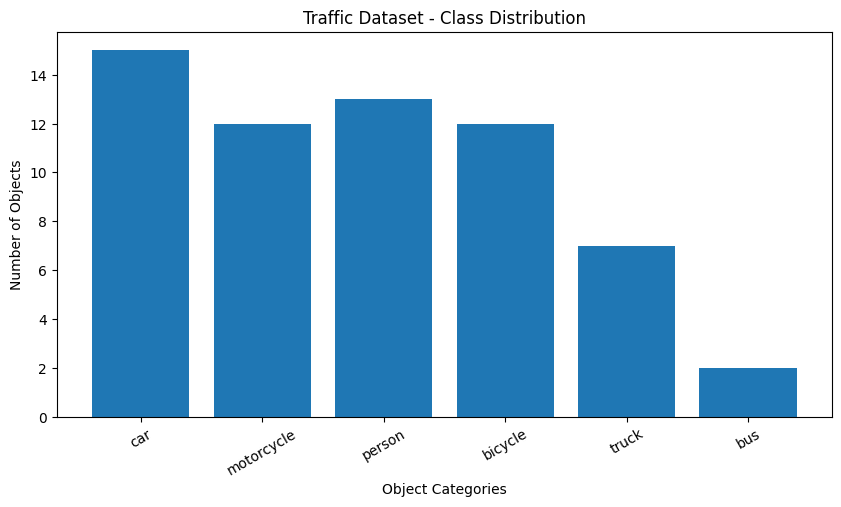

In [10]:
plt.figure(figsize=(10, 5))

plt.bar(class_counts.keys(), class_counts.values())

plt.title("Traffic Dataset - Class Distribution")
plt.xlabel("Object Categories")
plt.ylabel("Number of Objects")
plt.xticks(rotation=30)

plt.show()

In [11]:
image_class_counts = {name: 0 for name in categories.values()}

for image in coco_data["images"]:

    image_id = image["id"]

    present_classes = set()

    for annotation in coco_data["annotations"]:

        if annotation["image_id"] == image_id:
            class_name = categories[annotation["category_id"]]
            present_classes.add(class_name)

    for class_name in present_classes:
        image_class_counts[class_name] += 1

print("Number of images containing each category:")

for class_name, count in image_class_counts.items():
    print(class_name, ":", count)

Number of images containing each category:
car : 8
bus : 2
truck : 6
motorcycle : 8
person : 9
bicycle : 9


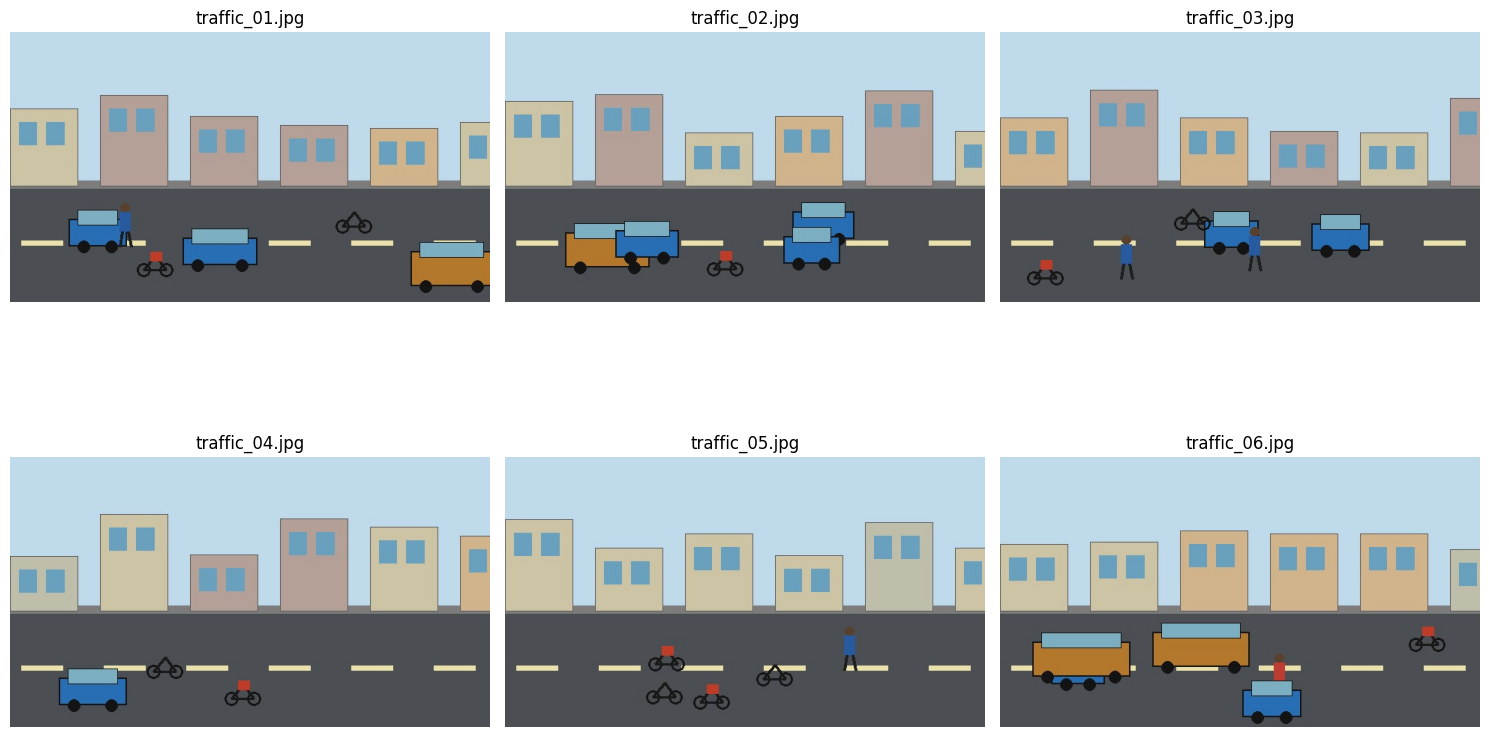

In [12]:
# Display first 6 images

image_files = coco_data["images"][:6]

plt.figure(figsize=(15, 10))

for i, image_info in enumerate(image_files):

    image_path = os.path.join(
        images_path,
        image_info["file_name"]
    )

    image = cv2.imread(image_path)

    # Convert BGR to RGB
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    plt.subplot(2, 3, i + 1)
    plt.imshow(image)
    plt.title(image_info["file_name"])
    plt.axis("off")

plt.tight_layout()
plt.show()

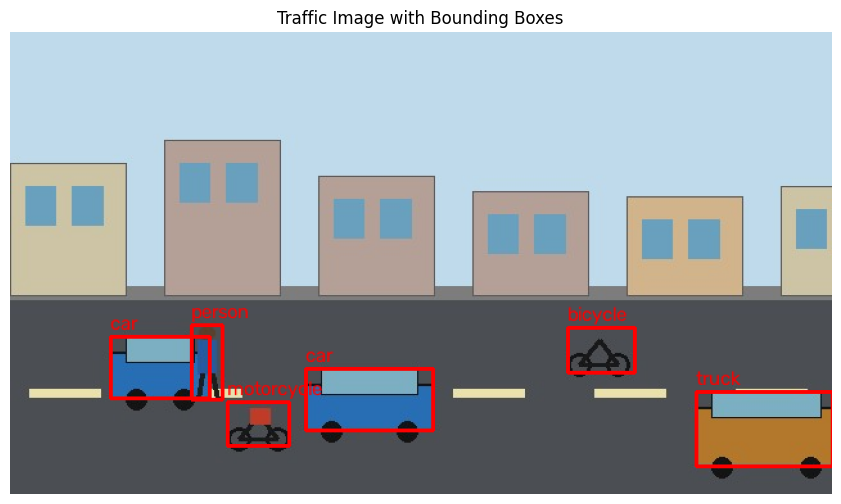

In [13]:
# Select one image
image_info = coco_data["images"][0]

image_path = os.path.join(
    images_path,
    image_info["file_name"]
)

image = cv2.imread(image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

# Find annotations belonging to this image
image_annotations = [
    ann for ann in coco_data["annotations"]
    if ann["image_id"] == image_info["id"]
]

# Draw bounding boxes
for ann in image_annotations:

    x, y, w, h = ann["bbox"]

    category_name = categories[ann["category_id"]]

    cv2.rectangle(
        image,
        (int(x), int(y)),
        (int(x + w), int(y + h)),
        (255, 0, 0),
        2
    )

    cv2.putText(
        image,
        category_name,
        (int(x), max(15, int(y) - 5)),
        cv2.FONT_HERSHEY_SIMPLEX,
        0.5,
        (255, 0, 0),
        1
    )

plt.figure(figsize=(12, 6))
plt.imshow(image)
plt.title("Traffic Image with Bounding Boxes")
plt.axis("off")
plt.show()

In [14]:
image_quality = []

for image_info in coco_data["images"]:

    image_path = os.path.join(
        images_path,
        image_info["file_name"]
    )

    image = cv2.imread(image_path)

    if image is None:
        image_quality.append({
            "Image": image_info["file_name"],
            "Status": "Corrupted",
            "Width": None,
            "Height": None
        })
        continue

    height, width = image.shape[:2]

    image_quality.append({
        "Image": image_info["file_name"],
        "Status": "Valid",
        "Width": width,
        "Height": height
    })

quality_df = pd.DataFrame(image_quality)

display(quality_df)

,Image,Status,Width,Height
0,traffic_01.jpg,Valid,640,360
1,traffic_02.jpg,Valid,640,360
2,traffic_03.jpg,Valid,640,360
3,traffic_04.jpg,Valid,640,360
4,traffic_05.jpg,Valid,640,360
5,traffic_06.jpg,Valid,640,360
6,traffic_07.jpg,Valid,640,360
7,traffic_08.jpg,Valid,640,360
8,traffic_09.jpg,Valid,640,360
9,traffic_10.jpg,Valid,640,360


In [15]:
blur_results = []

for image_info in coco_data["images"]:

    image_path = os.path.join(
        images_path,
        image_info["file_name"]
    )

    image = cv2.imread(image_path)

    if image is None:
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    blur_score = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()

    blur_results.append({
        "Image": image_info["file_name"],
        "Blur Score": round(blur_score, 2),
        "Quality": "Possibly Blurry" if blur_score < 100 else "Relatively Sharp"
    })

blur_df = pd.DataFrame(blur_results)

display(blur_df)

,Image,Blur Score,Quality
0,traffic_01.jpg,913.27,Relatively Sharp
1,traffic_02.jpg,949.03,Relatively Sharp
2,traffic_03.jpg,788.52,Relatively Sharp
3,traffic_04.jpg,813.84,Relatively Sharp
4,traffic_05.jpg,862.78,Relatively Sharp
5,traffic_06.jpg,1043.30,Relatively Sharp
6,traffic_07.jpg,1066.96,Relatively Sharp
7,traffic_08.jpg,888.51,Relatively Sharp
8,traffic_09.jpg,883.63,Relatively Sharp
9,traffic_10.jpg,837.95,Relatively Sharp


In [16]:
brightness_results = []

for image_info in coco_data["images"]:

    image_path = os.path.join(
        images_path,
        image_info["file_name"]
    )

    image = cv2.imread(image_path)

    if image is None:
        continue

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

    brightness = np.mean(gray)

    brightness_results.append({
        "Image": image_info["file_name"],
        "Brightness": round(brightness, 2)
    })

brightness_df = pd.DataFrame(brightness_results)

display(brightness_df)

,Image,Brightness
0,traffic_01.jpg,148.09
1,traffic_02.jpg,148.21
2,traffic_03.jpg,146.99
3,traffic_04.jpg,147.64
4,traffic_05.jpg,149.00
5,traffic_06.jpg,151.25
6,traffic_07.jpg,148.33
7,traffic_08.jpg,150.17
8,traffic_09.jpg,147.85
9,traffic_10.jpg,148.70


In [17]:
# Create image ID lookup
image_lookup = {
    image["id"]: image
    for image in coco_data["images"]
}

valid_category_ids = set(categories.keys())

validation_errors = []

for ann in coco_data["annotations"]:

    ann_id = ann["id"]
    image_id = ann["image_id"]
    category_id = ann["category_id"]

    # Check image ID
    if image_id not in image_lookup:
        validation_errors.append(
            f"Annotation {ann_id}: Invalid image ID"
        )
        continue

    # Check category ID
    if category_id not in valid_category_ids:
        validation_errors.append(
            f"Annotation {ann_id}: Invalid category ID"
        )
        continue

    image_info = image_lookup[image_id]

    width = image_info["width"]
    height = image_info["height"]

    x, y, box_w, box_h = ann["bbox"]

    # Check positive dimensions
    if box_w <= 0 or box_h <= 0:
        validation_errors.append(
            f"Annotation {ann_id}: Invalid bounding-box size"
        )

    # Check image boundaries
    if (
        x < 0 or y < 0 or
        x + box_w > width or
        y + box_h > height
    ):
        validation_errors.append(
            f"Annotation {ann_id}: Bounding box outside image"
        )

print("Total annotations:", len(coco_data["annotations"]))
print("Validation errors:", len(validation_errors))

if validation_errors:
    for error in validation_errors:
        print(error)
else:
    print("All annotations passed structural and geometric checks!")

Total annotations: 61
Validation errors: 0
All annotations passed structural and geometric checks!


In [18]:
total_images = len(coco_data["images"])
total_annotations = len(coco_data["annotations"])
total_categories = len(coco_data["categories"])

valid_images = sum(
    1 for item in image_quality
    if item["Status"] == "Valid"
)

corrupted_images = total_images - valid_images

print("=" * 45)
print("       DATASET AUDIT REPORT")
print("=" * 45)

print("Total Images:", total_images)
print("Total Annotations:", total_annotations)
print("Total Categories:", total_categories)

print("\nClass Distribution:")
for name, count in class_counts.items():
    print(name, ":", count)

print("\nImage Quality:")
print("Valid Images:", valid_images)
print("Corrupted Images:", corrupted_images)

print("\nAnnotation Validation:")
print("Total Errors:", len(validation_errors))

print("\nDataset Audit Completed!")
print("=" * 45)

       DATASET AUDIT REPORT
Total Images: 12
Total Annotations: 61
Total Categories: 6

Class Distribution:
car : 15
motorcycle : 12
person : 13
bicycle : 12
truck : 7
bus : 2

Image Quality:
Valid Images: 12
Corrupted Images: 0

Annotation Validation:
Total Errors: 0

Dataset Audit Completed!


In [19]:
# Save class distribution
class_df = pd.DataFrame(
    list(class_counts.items()),
    columns=["Category", "Object Count"]
)

class_df.to_csv(
    "/content/class_distribution.csv",
    index=False
)

# Save image quality report
quality_df.to_csv(
    "/content/image_quality_report.csv",
    index=False
)

# Save blur report
blur_df.to_csv(
    "/content/blur_report.csv",
    index=False
)

# Save brightness report
brightness_df.to_csv(
    "/content/brightness_report.csv",
    index=False
)

print("All audit reports saved successfully!")

All audit reports saved successfully!
